# Phase 5 — Extensions

Three extensions from the open-ended phase:

* **Realism effects** — light-time, annual aberration and equatorial coordinates, made by
  Tycho and reduced centrally by Jan for every strategy.
* **`sbi.npe`** — neural posterior estimation trained on simulations from Jan's own conic
  family (never from Tycho): an amortized round over the whole prior, then truncated rounds
  focused on the data.
* **`llm.hypothesize`** — Claude proposes model families (registered ones, or new central
  force laws) from residual summaries; Jan fits them and compares evidences. Every call is
  cached for replay.

Plus an interactive explorer over any sweep's results (`explorer.html`, linked from each
report). Sweeps: `bench/realism.yaml`, `bench/sbi_npe.yaml`, `bench/llm_hypothesize.yaml`.

In [1]:
import os, warnings
os.chdir('/home/dylan/Projects/jan-and-tycho')
os.environ.setdefault("MPLBACKEND", "Agg")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160)

from IPython.display import Video
def results(name):
    p = Path("runs/sweeps") / name / "results.parquet"
    if not p.exists():
        print(f"(missing) run: jt bench sweep bench/{name}.yaml --workers 14 && jt bench report runs/sweeps/{name}")
        return None
    return pd.read_parquet(p)
def show(name, fig, width=760):
    p = Path("runs/sweeps") / name / "figures" / fig
    display(Image(filename=str(p), width=width)) if p.exists() else print(f"(missing figure {p})")
def cell_fig(name, scenario, label, fig, seed=0, width=760):
    """A per-run figure (or MP4) from a sweep cell."""
    p = Path("runs/sweeps") / name / "cells" / scenario / "base" / str(seed) / "rudolf" / label / "figures" / fig
    if not p.exists():
        print(f"(missing figure {p})")
    elif p.suffix == ".mp4":
        display(Video(str(p), embed=True, width=width))
    else:
        display(Image(filename=str(p), width=width))

## Realism: light-time, aberration, equatorial frame

Tycho publishes *apparent* directions: the body where it was when the light left it
(τ = Δ/c, ~3–22 min for Mars), tilted by the observer's velocity (κ ≈ 20.5″), optionally as
right ascension/declination. `PublicMeta.realism` states which effects are present — a
catalogue says what it reports — and Jan's `RealismAdapter` wraps every strategy:

* the frame rotation is undone exactly;
* aberration with a known observer is removed exactly before fitting;
* light-time (and aberration when the observer is inferred, T2) uses a two-pass differential
  correction: the first fit's heliocentric positions give each observation's correction;
* predictions are mapped back to apparent directions in the published frame.

`realism: ignore` skips the physical corrections, measuring the bias they would leave.
`scenarios/realism_mars.yaml` has modern 1″ astrometry.

In [2]:
df = results("realism")
if df is not None:
    d = df[df.status == "ok"]
    display(d.pivot_table(index="label", columns=["realism.light_time", "realism.aberration"],
                          values="holdout_rms_arcsec", aggfunc="median").round(3))

realism.light_time             False          True         
realism.aberration             False   True   False   True 
label                                                      
bayes.mcmc[realism=ignore]     0.102  16.089  9.073  25.278
bayes.mcmc[realism=model]      0.102   0.113  0.106   0.105
classical.lsq[realism=ignore]  0.107  16.068  9.063  25.045
classical.lsq[realism=model]   0.107   0.107  0.107   0.107
ptolemy.fourier                3.634   3.634  4.554   4.554

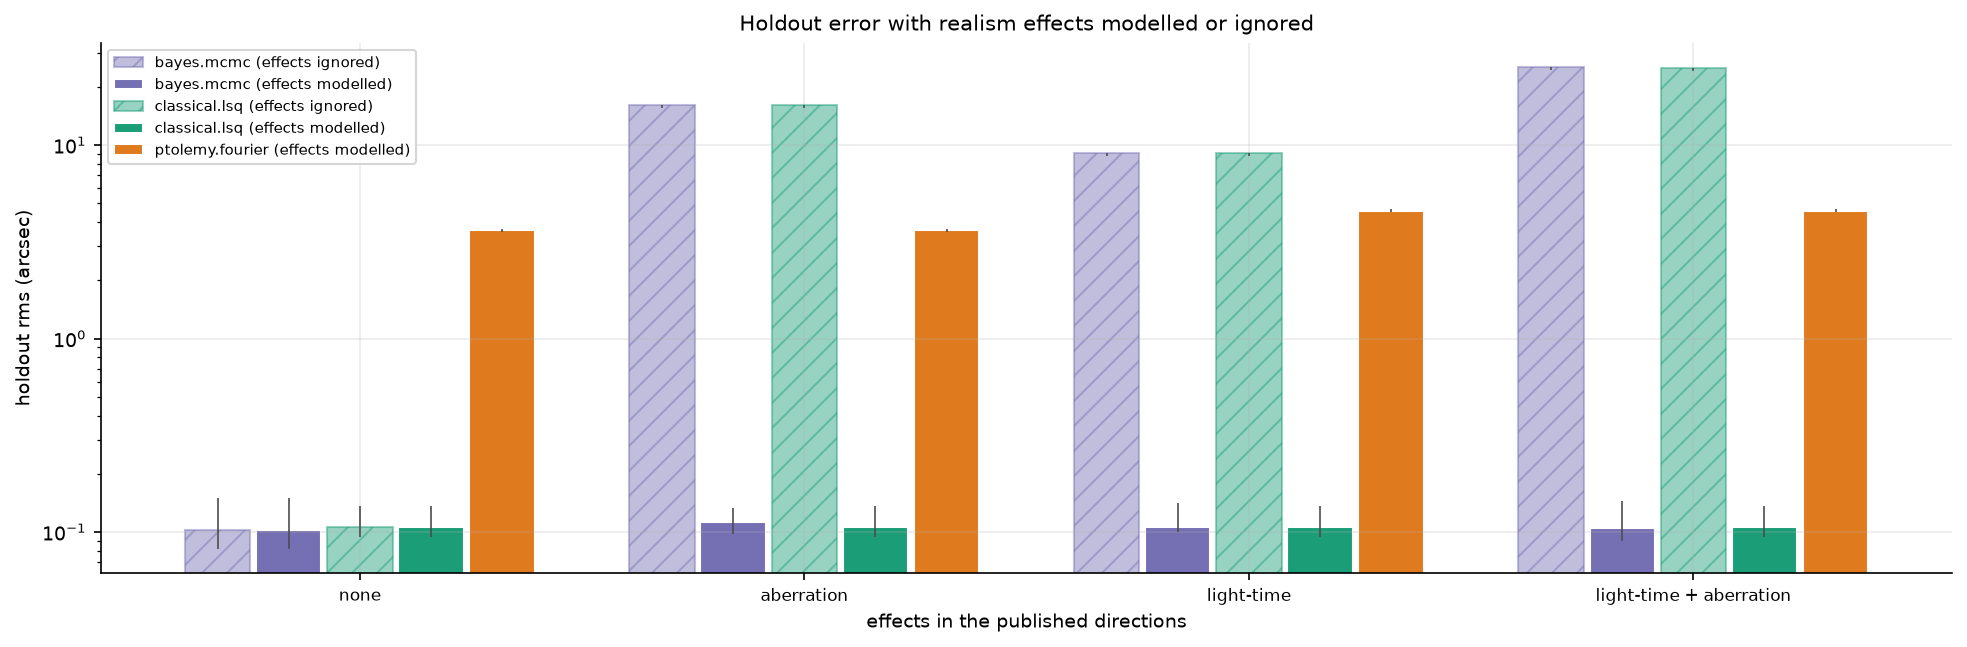

In [3]:
show("realism", "realism_bias.png", 950)

Modelled, the effects cost nothing: `classical.lsq` and `bayes.mcmc` stay at ~0.1″ in every
combination. Ignored, light-time leaves ~9″ and aberration ~16″ (both: ~25″), and the
predictive intervals stop covering the holdout. `ptolemy.fourier` has no heliocentric model,
so it cannot represent light-time; its aberration is still removed exactly. At T2
(`mars_unknown_earth`, observer inferred) the corrections work through the inferred Earth
(0.15″ modelled vs 11.5″ ignored on one seed); part of the aberration is absorbed into the
inferred Earth's orbit there, since the aberrated Sun stream looks like a shift in its phase.

## `sbi.npe`: amortized vs per-scenario posteriors

Simulations come from Jan's `conic-elliptic` family, at the published epochs and seen from
the published Earth, with tangent-plane noise at σ (published, or a MAP estimate); data are
summarized as mean directions in ~96 time bins. Round 1 trains a masked autoregressive flow
on the whole prior: an **amortized** posterior. Each later round retrains on the prior
truncated to the previous posterior's 1 − 2·10⁻³ box (widened by 50 %): a **per-scenario**
posterior. Rounds stop when the box stops shrinking.

In [4]:
df = results("sbi_npe")
if df is not None:
    d = df[df.status == "ok"]
    rows = []
    for lab, g in d.groupby("label"):
        row = {"strategy": lab, "seeds": len(g), "runtime (s)": g.runtime_s.median(),
               "holdout RMS (″)": g.holdout_rms_arcsec.median(), "pred. cover95": g.pred_cover95.mean()}
        for el in ["q", "e", "i", "Omega", "omega", "t_p"]:
            if f"in95_{el}" in g:
                row[f"cover95 {el}"] = g[f"in95_{el}"].dropna().astype(float).mean()
        rows.append(row)
    display(pd.DataFrame(rows).set_index("strategy").round(3))

,seeds,runtime (s),holdout RMS (″),pred. cover95,cover95 q,cover95 e,cover95 i,cover95 Omega,cover95 omega,cover95 t_p
strategy,,,,,,,,,,
bayes.mcmc,10,36.348,6.149,0.961,1.000,1.000,1.000,1.000,1.000,1.0
sbi.npe[rounds=1],10,53.739,287807.775,0.539,0.300,1.000,0.000,1.000,1.000,1.0
sbi.npe[rounds=8],9,496.294,6.022,0.718,0.889,0.889,0.889,0.778,0.889,1.0


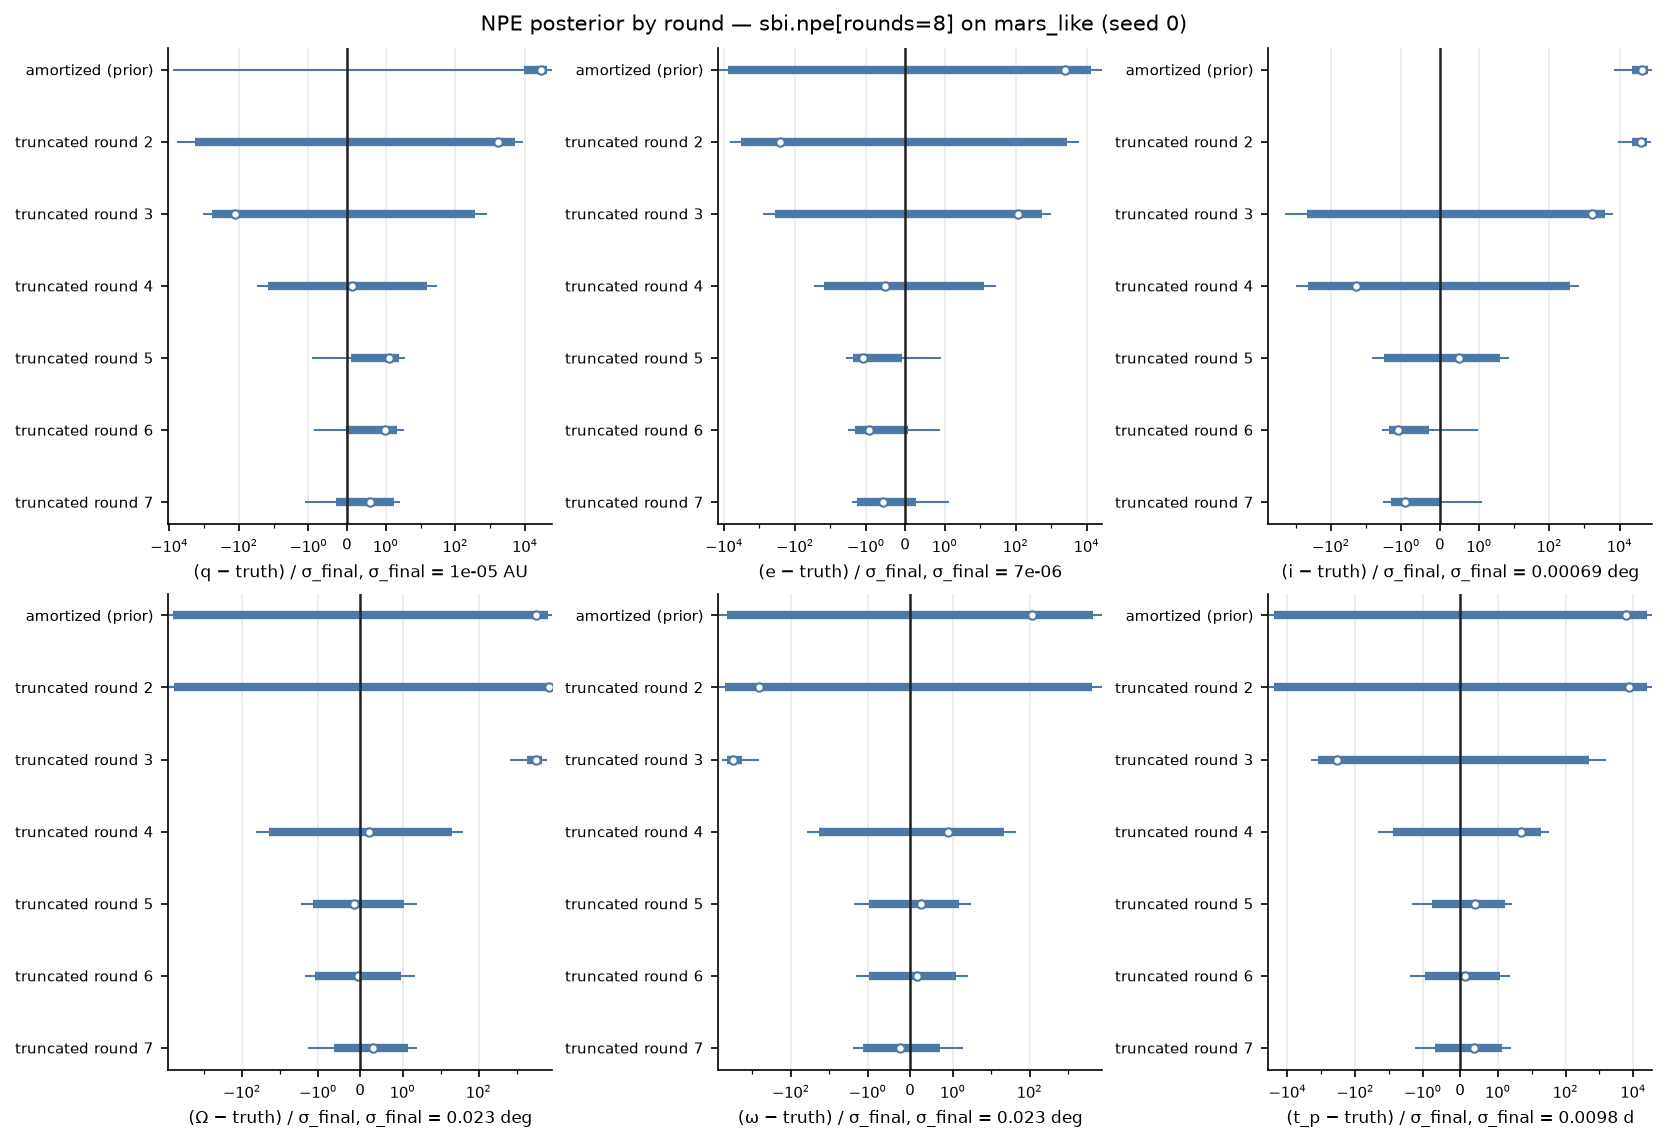

In [5]:
cell_fig("sbi_npe", "mars_like", "sbi.npe[rounds=8]", "npe_rounds.png", width=950)

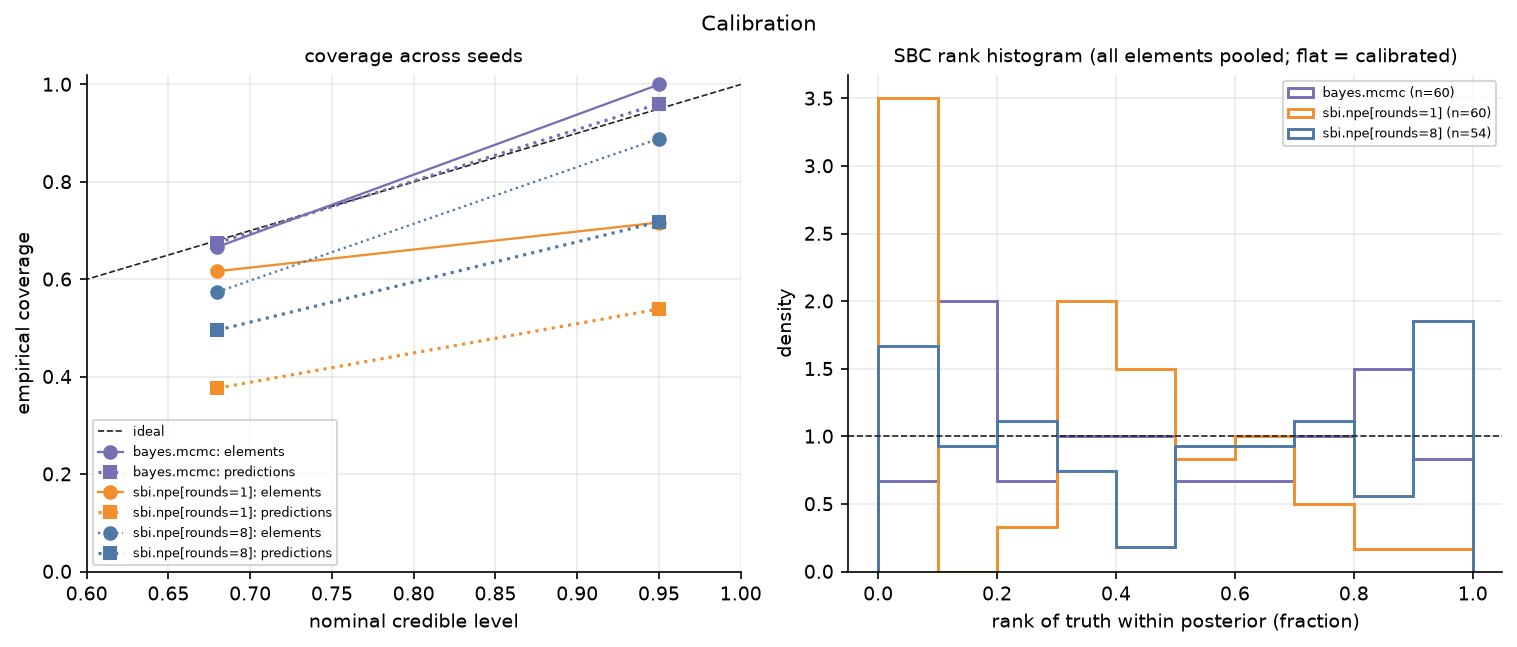

In [6]:
show("sbi_npe", "calibration.png", 900)

The amortized round is ~10⁴ times wider than the final one in q, and not even calibrated:
its median inclination lands at 30–100° (truth 1.9°), so it covers q in 3 of 10 seeds and i
in none. Six parameters over the whole prior cannot be resolved to 60″ data with 20,000
simulations. Truncation reaches the data's precision in six or seven rounds (120–140k
simulations; ~3 min alone on the CPU, ~8 min while sharing it in the sweep, and one seed
exceeded the 30-minute timeout). Its predictions are as accurate as emcee's (median holdout
6.0″ vs 6.1″), but its intervals are **overconfident**: the 95 % element intervals cover the
truth in 78–89 % of seeds (emcee: 100 %) and the 95 % predictive intervals 72 % of holdout
observations (emcee: 96 %). Documented limitation: no ensembling or calibration step.

## `llm.hypothesize`: propose → fit → compare

Each iteration sends Claude (`claude-opus-5-5`, structured JSON output) a deterministic,
rounded summary of the current best fit: residual RMS against σ, residuals binned by time and
by heliocentric distance, the residual periodogram, and the apsidal precession between
ellipse fits to the two halves of the arc. It replies with up to three candidates — a
registered family by name, or a new central law f(r) with bounded parameters — or stops.
Jan fits each by MAP (Laplace evidence) and, at the end, compares the leaders by nested
sampling.

* **Caching.** Requests are keyed by a hash of their exact body, so a re-run (or anyone with
  `runs/llm_cache`) replays without API calls; `offline: true` turns a cache miss into an
  error.
* **Safety.** A proposed law is text from outside Jan: every token is whitelisted (numbers,
  arithmetic, `exp/log/sqrt/tanh/pi`, `r`, `GM` and the declared parameter names) before
  sympy parses it. The test suite feeds it `__import__('os')…`, which is refused.
* **No leakage.** The prompt carries only `PublicMeta` and summaries of the observations —
  no scenario name, description or truth.

In [7]:
df = results("llm_hypothesize")
if df is not None:
    d = df[df.status == "ok"]
    display(d[["scenario", "selected_family", "answer", "symbolic", "holdout_rms_arcsec"]])
    for sc in d.scenario.unique():
        cell_fig("llm_hypothesize", sc, "llm.hypothesize", "hypothesis_history.png", width=950)
else:
    print("Not run here: a first run calls the Anthropic API (needs credentials, billed).")

(missing) run: jt bench sweep bench/llm_hypothesize.yaml --workers 14 && jt bench report runs/sweeps/llm_hypothesize
Not run here: a first run calls the Anthropic API (needs credentials, billed).
